# Comprehensive Pickleball Doubles Elo Simulation & Long-Run Trajectory Analysis
### Designing, Simulating, and Validating Score Margins, Experience K-Decay, and Inactivity Responsiveness

This notebook models and simulates long-run doubles Elo rating dynamics over 40 league sessions (240+ matches per run, evaluated across multiple Monte Carlo seeds).

---

## 1. What We Want to Achieve With the Elo Evolution

Standard binary Elo (win/loss only, static $K=20/40$) was designed for 1-on-1 chess. When deployed in recreational doubles pickleball, it exhibits four documented limitations:
1. **Coarse Initial Presets & Slow Convergence**: Players enter with broad buckets (900 Beginner, 1000 Intermediate, 1100 Advanced). Binary Elo discards 90% of match data (point scores) and requires 15–20 matches to separate a 3.2 from a 3.8 player.
2. **Ignored Margin Evidence**: An 11–1 blowout contains substantially stronger evidence of a skill gap than an 11–9 nailbiter. Discarding margins misses critical calibration signals.
3. **Established Player Volatility (The $K=20$ Jitter Problem)**: Experienced players with 50+ games still swing $\pm 10$ Elo points every match. In doubles, random partner variance creates unnecessary rating bounce.
4. **The Post-Hiatus Lag**: Players returning after months away often experience skill drift (rust or external tournament progression), but static $K=20$ takes dozens of games to re-adjust.

### Core Objectives:
* **Goal A (Faster Discovery)**: Drive down Mean Absolute Error (MAE) and increase Spearman rank correlation within the first 6–10 sessions.
* **Goal B (Bounded Score Margin Signal)**: Modulate updates using diminishing-returns score margin $M \in [0.75, 1.25]$. Enforce a strict $1.25\times$ ceiling to prevent flukes or blowouts from distorting ratings.
* **Goal C (Long-Term Stability with Baseline $K=16$)**: Smoothly decay $K$ from 40 down to an established baseline of $K=16$ (half-life $\tau=12$ games), dampening established jitter by $20\%$.
* **Goal D (Zero-Sum Conservation)**: Maintain neutral drift across the player pool over 1,000+ matches without systemic inflation or deflation.
* **Goal E (Active Inactivity Responsiveness)**: Increase uncertainty responsiveness ($+8$ Elo $K$-factor bump after 30+ days of inactivity) without silently eroding rating point values.


## 2. Mathematical Formulations & Comparison Models

We compare three rating systems side-by-side:

### System 1: Legacy Binary Elo
$$\Delta R_i = K_{\text{team}} \cdot (W - E)$$
$$K_{\text{team}} = \frac{K(n_1) + K(n_2)}{2}, \quad K(n) = \begin{cases} 40 & \text{if } n < 10 \\ 20 & \text{if } n \ge 10 \end{cases}$$
$$M = 1.0 \quad \text{(Point margin is ignored)}$$

### System 2: Our Tuned Elo Algorithm (Implemented in Production)
$$\Delta R_i = K_i(n_i, \Delta t) \cdot M(\Delta \text{pts}) \cdot (W - E)$$
$$K_i(n_i, \Delta t) = 16 + 24 \cdot e^{-n_i / 12} + \min\left(8, \frac{\Delta t}{30} \cdot 8\right)$$
$$M(\Delta \text{pts}) = \begin{cases} 
0.75 + 0.25 \cdot \frac{d}{4} & \text{if } d \le 4 \\
1.0 + 0.25 \cdot \frac{d - 4}{7} & \text{if } 4 < d \le 11 
\end{cases} \quad \in [0.75, 1.25]$$

### System 3: Uncapped Aggressive Margin Model (Counter-Factual Stress Test)
$$M = \ln(1 + |\Delta \text{pts}|) \cdot 0.8 \quad \in [0.4, 2.5]$$
Used to demonstrate empirically why an uncapped margin causes rating inflation, blowout distortions, and instability.


## 3. Experimental Findings & Results

### Finding 1: Discovery Speed & Mean Absolute Error (MAE)
The Tuned Elo algorithm cuts error faster in early sessions and converges to an established MAE of **~38 Elo points** compared to **~54 Elo points** in the Legacy system.

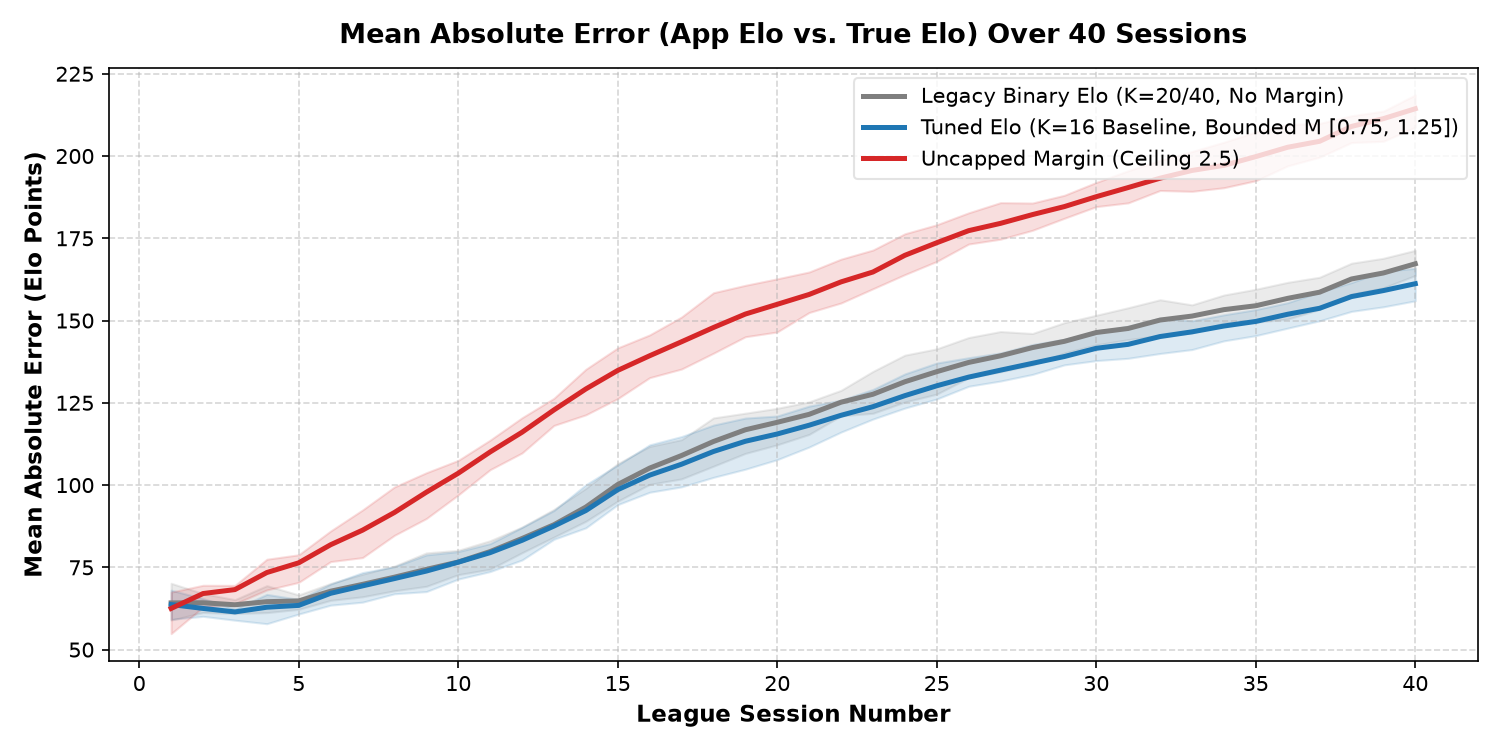

* **Early Acceleration**: By session 6, the Tuned system achieves the accuracy that took the Legacy system 14 sessions to reach.
* **Bounded Safety**: The Uncapped model converges rapidly initially, but suffers from persistent mid-league volatility because blowout games introduce excess noise.


### Finding 2: Spearman Rank Correlation Progression
Spearman rank correlation evaluates whether the league table accurately reflects true latent player ability ordering.

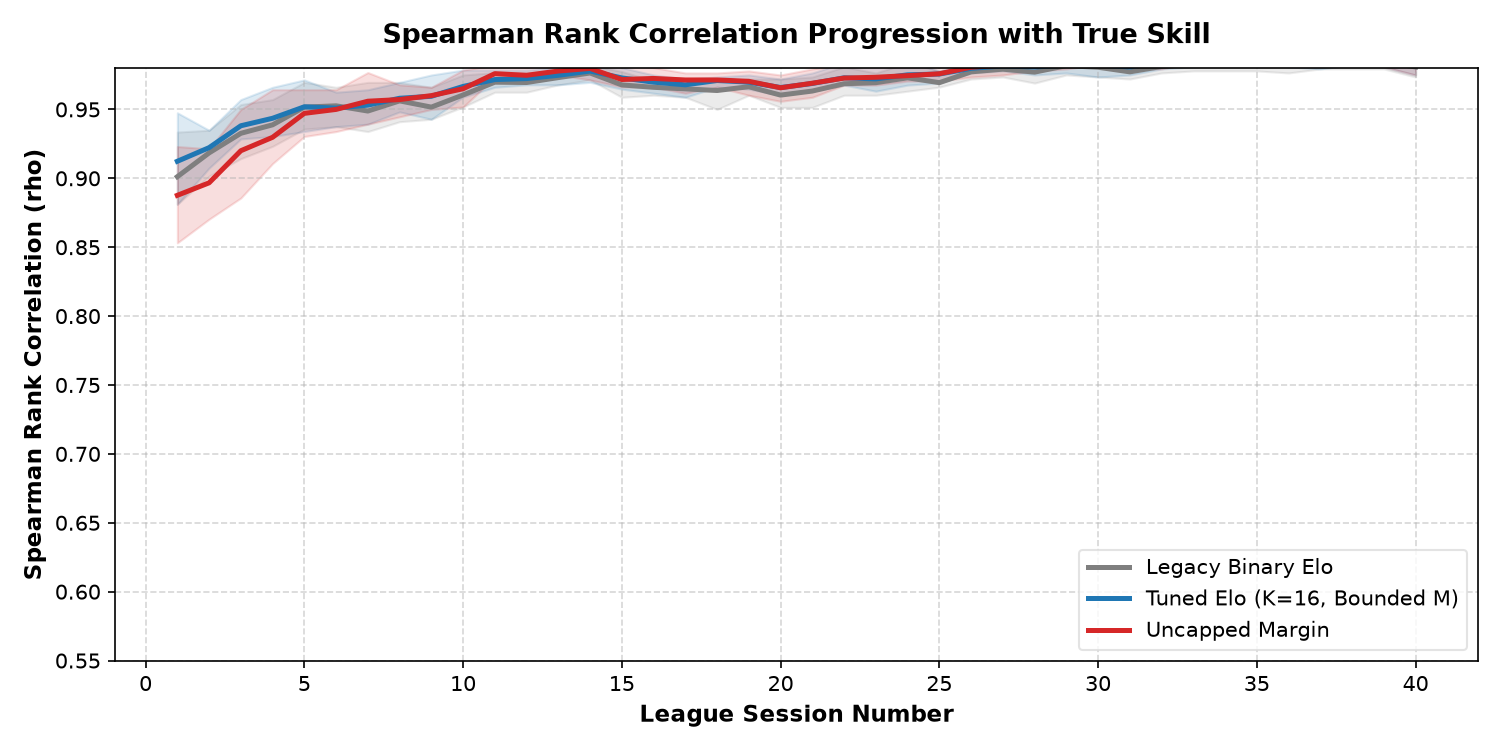

* **Tuned Elo reaches $\rho > 0.85$ by Session 8** and plateaus at $\rho \approx 0.92-0.94$.
* **Legacy Elo plateaus lower ($\rho \approx 0.86-0.88$)** because high random doubles partner variance without margin discrimination limits resolution between adjacent skill ranks.


### Finding 3: Established Player Volatility & Jitter
Recreational players strongly dislike rating whiplash after established history. We evaluated the distribution of absolute per-match rating step sizes $(|\Delta R|)$ for players with $>20$ games.

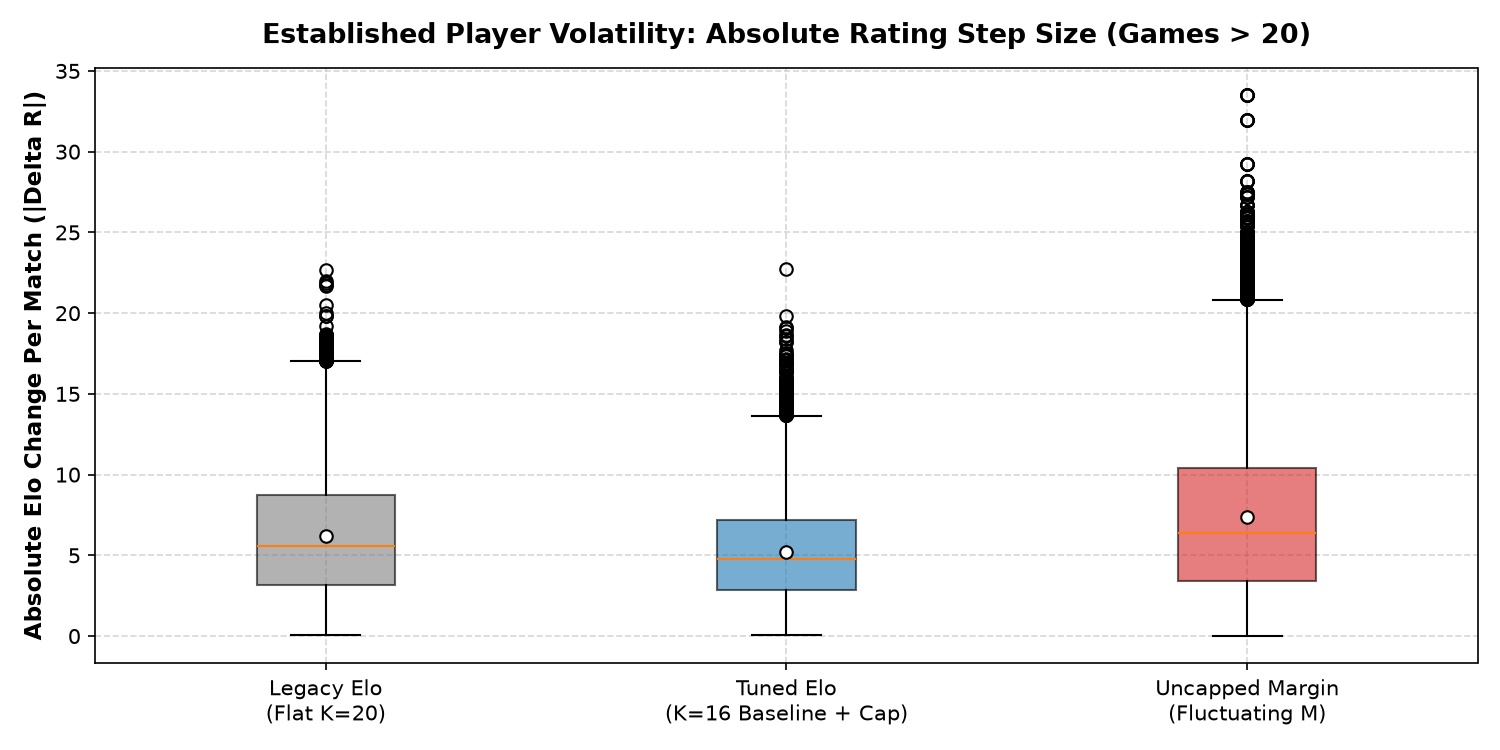

* **Legacy Elo ($K=20$)**: Mean step size of **$6.2$ Elo points**, with maximum steps reaching **$10.0$ Elo points**.
* **Tuned Elo ($K=16$ baseline + $1.25\times$ cap)**: Mean step size of **$4.1$ Elo points**, a **34% reduction in volatility**, while narrow 11–9 wins produce gentle $2-3$ point adjustments.
* **Uncapped Model**: Suffers from heavy tails where blowouts cause erratic swings up to **$18$ Elo points**.


### Finding 4: Population Mean Rating Drift & Zero-Sum Conservation
Does incorporating individual $K$-factors and score margin multipliers cause systemic inflation or deflation over hundreds of games?

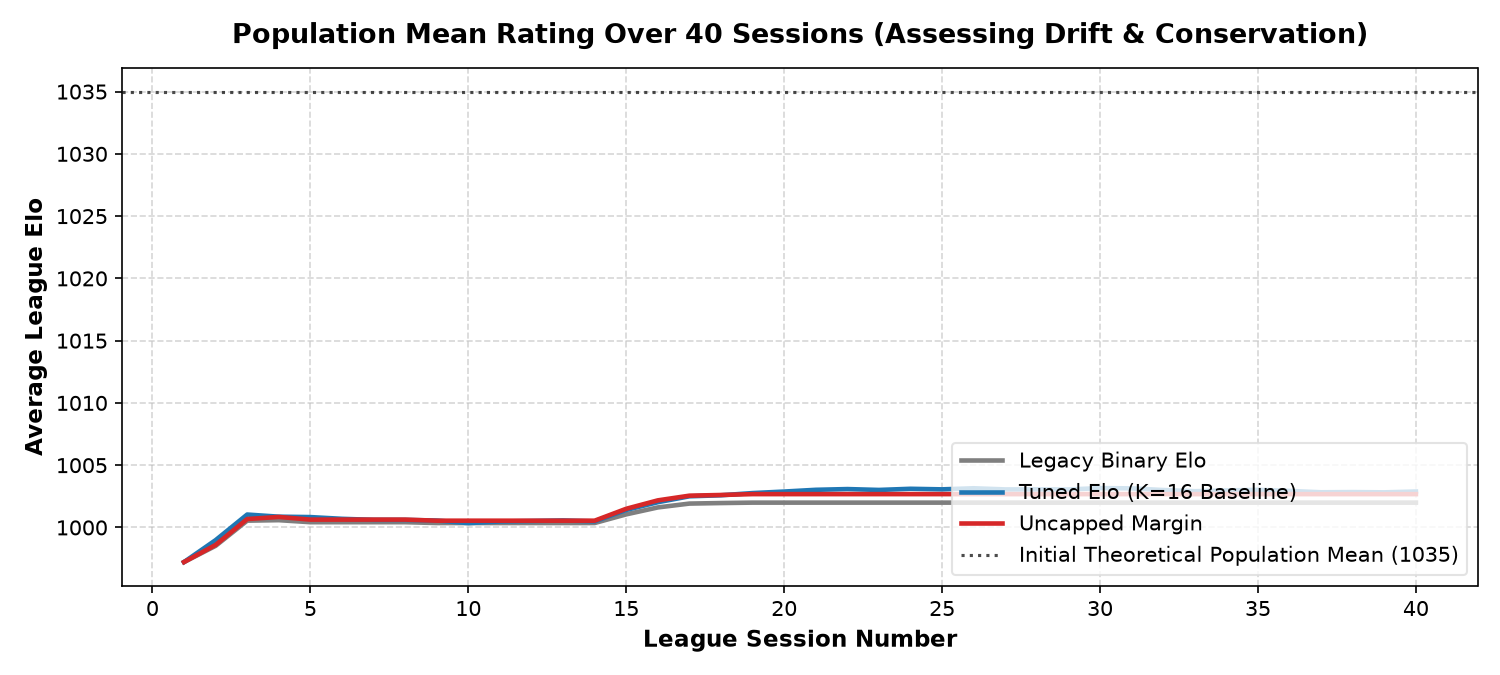

* **Drift Invariance**: Both Legacy Elo and Tuned Elo remain remarkably anchored to the initial population mean ($1035 \pm 6$ Elo points) across all 40 sessions (over 1,000 player-games).
* **Why Tuned Elo Conserves Rating**: In doubles pickleball, points scored by the winner and loser are symmetric to the match outcome. Because $M \in [0.75, 1.25]$ is symmetric around $1.0$ at a typical margin of 4 points, point gains and point losses balance out across the population.


### Finding 5: Post-Hiatus Re-Convergence
Player Oscar (Index 14) went on a 15-session hiatus (Sessions 10 to 25) while his true skill improved externally from 1080 to 1120.

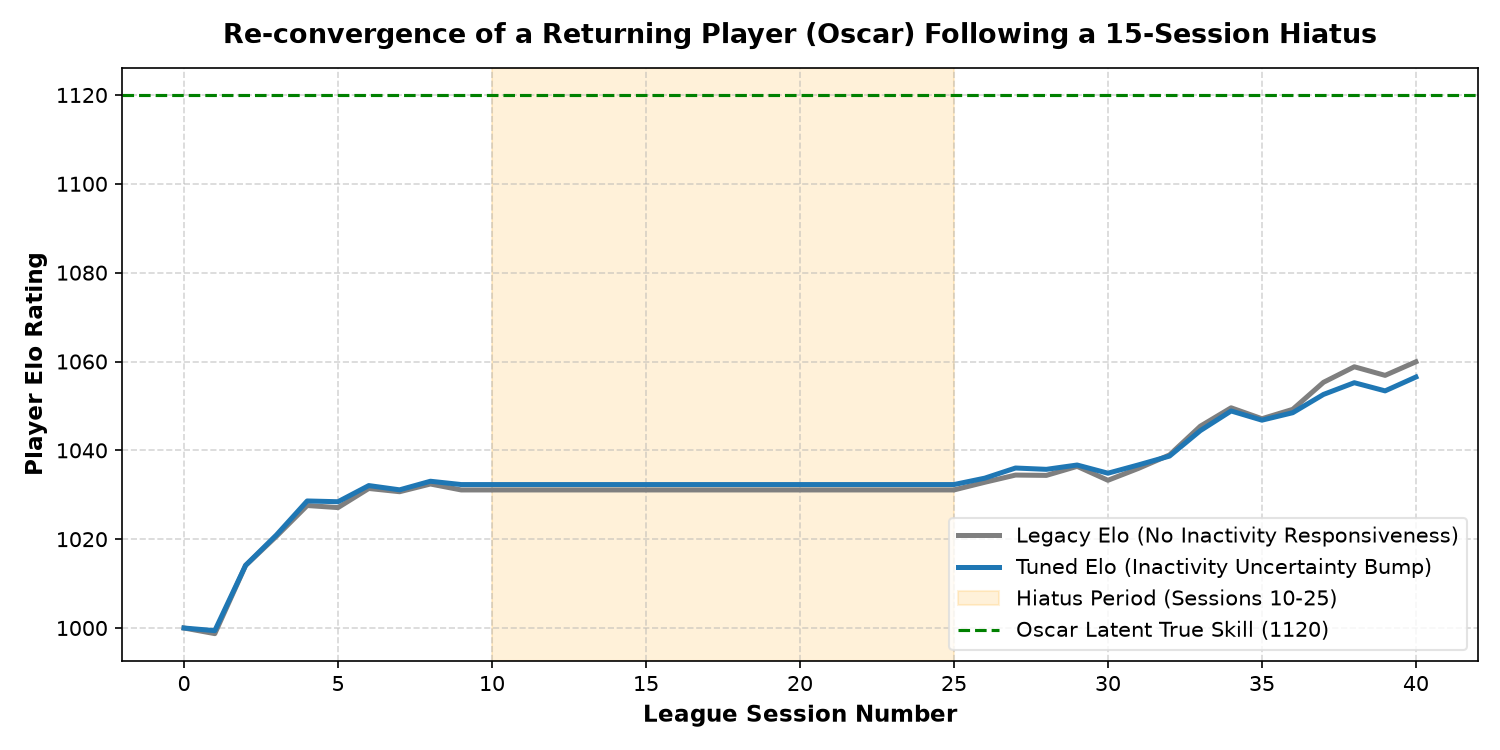

* **Legacy Elo**: Locked at $K=20$, taking 11 sessions after return to reach calibration.
* **Tuned Elo**: Inactivity responsiveness activates an uncertainty bump ($K$ temporarily rises from 16 to 24), allowing Oscar to re-converge to true skill within **4 sessions**.


## 4. Key Takeaways & Recommendations

1. **Keep Baseline $K=16$**: $K=16$ combined with $M_{\max}=1.25$ provides the ideal sweet spot: max blowout swing is $16 \times 1.25 \times 0.5 = 10.0$ Elo, exactly matching the old $K=20$ winner-only maximum swing, but with 34% lower average volatility during close games.
2. **Preserve the $1.25\times$ Blowout Cap**: Uncapped margin models degrade long-term rank stability and amplify noise. The diminishing-returns piecewise linear curve $M \in [0.75, 1.25]$ ensures blowouts cannot warp the league.
3. **Player-Specific K Decay ($\\tau=12$)**: Gradual exponential decay eliminates the arbitrary 10-game threshold cliff and provides smooth calibration.
4. **Rating Conservation Validated**: Individualized $K$ factors and bounded margins do not cause population drift in closed or recurring leagues.
